# 模型推理时间

In [ ]:
from pathlib import Path

from provider import *
import torch
import torch.utils.benchmark as benchmark
import csv
from hydra import initialize, compose
from hydra.core.hydra_config import HydraConfig

DEVICE = 'cuda:1'

dataset_model = {
    'RML128': ['CNN1D', 'MCLDNN', 'FEA_T', 'SigFormer', 'AMC_Net', 'ALWNN', 'ULCNN', 'WaveletCNN'],
    'RML128b': ['CNN1D', 'MCLDNN', 'FEA_T', 'SigFormer', 'AMC_Net', 'ALWNN', 'ULCNN', 'WaveletCNN'],
    'RML1024': ['CNN1D', 'MCLDNN', 'FEA_T', 'SigFormer', 'AMC_Net', 'ALWNN', 'ULCNN', 'WaveletCNN'],
    'TechRec': ['CNN1D', 'MCLDNN', 'FEA_T', 'SigFormer', 'AMC_Net', 'ALWNN', 'ULCNN', 'WaveletCNN']
}
keys = dataset_model.keys()

for key in keys:
    for model in dataset_model[key]:
        with initialize(version_base=None, config_path="conf"):
            cfg = compose(config_name='config.yaml', return_hydra_config=True,
                          overrides=[
                              f'dataset={key}',
                              f'model={model}',
                              'dataset.batch_size=16',
                          ])
            HydraConfig.instance().set_config(cfg)

        _, batchld, _, classes = SigData_provider('test', cfg)
        model = modelloader(cfg).to(DEVICE)
        model.eval()
        # torch.set_grad_enabled(False)
        
        data = next(iter(batchld))[0].to(DEVICE).float()
        t = benchmark.Timer(
            stmt='model(data)',
            setup='from __main__ import model, data',
            num_threads=1,
            label=cfg.dataset['name'],
            sub_label=cfg.model['name'],
            description='Single'
        )
        res = t.timeit(100)
        time = res.median * 1e3
        print(f"{cfg.dataset['name']}_{cfg.model['name']}:", f"{time:.3f} ms")

        with open(Path('./plot') / 'time.csv', 'a', newline='') as f:
            writer = csv.writer(f)
            if f.tell() == 0:
                writer.writerow(['dataset', 'model', 'time'])
            writer.writerow([cfg.dataset['name'], cfg.model['name'], f"{time:.3f} ms"])


# SNR  混淆矩阵 数据计算
提供模型路径，即可测试

In [ ]:
import csv, torchmetrics, torch, json
from omegaconf import OmegaConf
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from provider import *
from inference_class import InferenceClass
from utils.metrics import AccuracyBySNR

FONTS = {
    '等宽': 'Noto Sans Mono CJK SC',
    '宋体': 'Noto Serif CJK SC',
    '黑体': 'Noto Sans CJK SC',
    '思源宋体': 'Source Han Serif SC',
    '思源等宽': 'Source Han Mono SC',
    '微软雅黑': 'SimHei',
    'Times New Roman': 'Times New Roman'
}
model_dirs = [
        #TechRec
        # '/home/mount_data/bsh/PSGFormer/outputs/WaveletCNN/TechRec__0.8837',
        # '/home/mount_data/bsh/PSGFormer/outputs/CNN1D/TechRec__version_1',
        # '/home/mount_data/bsh/PSGFormer/outputs/MCLDNN/TechRec__version_1',
        
        # '/home/mount_data/bsh/PSGFormer/outputs/FEA_T/TechRec__version_1',
        # '/home/mount_data/bsh/PSGFormer/outputs/SigFormer/TechRec__version_1',
        # '/home/mount_data/bsh/PSGFormer/outputs/IQFormer/TechRec_STFT__version_3',
        # '/home/mount_data/bsh/PSGFormer/outputs/ALWNN/TechRec__version_2',
        # '/home/mount_data/bsh/PSGFormer/outputs/ULCNN/TechRec__version_1',
        
        #RML128
        # '/home/mount_data/bsh/PSGFormer/outputs/WaveletCNN/RML128__0.633',
        # '/home/mount_data/bsh/PSGFormer/outputs/CNN1D/RML128__version_1',
        # '/home/mount_data/bsh/PSGFormer/outputs/IQFormer/RML128_STFT__version_1',
        # '/home/mount_data/bsh/PSGFormer/outputs/ALWNN/RML128__version_2',
        # '/home/mount_data/bsh/PSGFormer/outputs/ULCNN/RML128__version_1',
        
        #RML128b
        # '/home/mount_data/bsh/PSGFormer/outputs/WaveletCNN/RML128b__0.652',
        # '/home/mount_data/bsh/PSGFormer/outputs/CNN1D/RML128b__version_1',
        # '/home/mount_data/bsh/PSGFormer/outputs/IQFormer/RML128b_STFT__version_1',
        # '/home/mount_data/bsh/PSGFormer/outputs/ALWNN/RML128b__version_2',
        # '/home/mount_data/bsh/PSGFormer/outputs/ULCNN/RML128b__version_1',
        
        #RML1024
        '/home/mount_data/bsh/PSGFormer/outputs/WaveletCNN/RML1024__17_0.621',
        '/home/mount_data/bsh/PSGFormer/outputs/CNN1D/RML1024__version_1',
        '/home/mount_data/bsh/PSGFormer/outputs/IQFormer/RML1024_STFT__version_5',
        '/home/mount_data/bsh/PSGFormer/outputs/ALWNN/RML1024__version_1',
        '/home/mount_data/bsh/PSGFormer/outputs/ULCNN/RML1024__version_2',
        
        
]
DEVICE = 'cuda:1'  #因为循环多次加载模型 jupyter不自动释放gpu（无解）,初始化一个变量来防止放置到多个gpu上
SNR=[-20,-18,-16,-14,-12,-10,-8,-6,-4,-2,0,2,4,6,8,10,12,14,16,18,20,22,24,26,28,30]

for model_dir in model_dirs:
    
    cfg = OmegaConf.load(Path(model_dir) / 'config.yaml')
    cfg.dataset.snr=SNR
    #数据集
    _, batchld, _, classes = SigData_provider('test', cfg)
    #模型
    model = InferenceClass(model_dir, DEVICE)
    #指标混淆矩阵 snr曲线
    cfm=torchmetrics.ConfusionMatrix(task='multiclass',num_classes=cfg.dataset['num_classes'], normalize='true').to(DEVICE)
    accBySnr=AccuracyBySNR(snrs=SNR).to(DEVICE)
    for batch in batchld:
        output=model.infer_step(batch)
        logits,pred, label = output['logits'],output['pred'], output['target']
        
        cfm.update(pred, label[:, 1])
        accBySnr.update(logits,snr=label[:,0],label=label[:,1])
    
    
    matrix_res=(cfm.compute()*100).int()
    accbysnr_res=accBySnr.compute()
    
    fig,ax=cfm.plot(val=matrix_res,labels=classes,cmap='Blues')
    #调整一下图像
    fig.set_size_inches(8,8)
    ax.set_xticklabels(labels=classes,rotation=45, fontsize=10)
    ax.set_yticklabels(labels=classes,rotation=0, fontsize=10)
    
    accBySnr.plot()
    plt.show()
    
    #保存混淆矩阵
    with open(Path('./plot') / f'{cfg.dataset["name"]}_cfmatrix.json', 'a') as f:
        record = {"label": classes, "model": cfg.model['name'], "matrix": matrix_res.tolist()}
        f.write(json.dumps(record) + '\n')


    #保存多模型每个SNR上的结果
    with open(Path('./plot') / f'{cfg.dataset["name"]}__bySNR.csv', 'a', newline='') as f:
        acc={'model':cfg.model['name']}
        acc.update(accbysnr_res)
        writer = csv.DictWriter(f, fieldnames=acc.keys())
        if f.tell() == 0:
            writer.writeheader()
        writer.writerow(acc)

# 可视化卷积核和特征图（时频图）

In [ ]:

import csv, torchmetrics, torch, json
from omegaconf import OmegaConf
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from provider import *
from inference_class import InferenceClass
from utils.metrics import AccuracyBySNR
from pywt import cwt
from scipy.signal import stft
FONTS = {
    '等宽': 'Noto Sans Mono CJK SC',
    '宋体': 'Noto Serif CJK SC',
    '黑体': 'Noto Sans CJK SC',
    '思源宋体': 'Source Han Serif SC',
    '思源等宽': 'Source Han Mono SC',
    '微软雅黑': 'SimHei',
    'Times New Roman': 'Times New Roman'
}
model_dirs = [
    # '/home/mount_data/bsh/PSGFormer/outputs/WaveletCNN/RML128__0.636',
    # '/home/mount_data/bsh/PSGFormer/outputs/WaveletCNN/TechRec__0.8837',
    '/home/mount_data/bsh/PSGFormer/outputs/WaveletCNN/RML1024__21_0.623'
]
DEVICE = 'cuda:1'  #因为循环多次加载模型 jupyter不自动释放gpu（无解）,初始化一个变量来防止放置到多个gpu上
SNR=[-4]

for model_dir in model_dirs:
    
    cfg = OmegaConf.load(Path(model_dir) / 'config.yaml')
    cfg.dataset.snr=SNR
    #数据集
    datasets, batchld, _, classes = SigData_provider('test', cfg)
    #模型
    model = InferenceClass(model_dir, DEVICE).get_model()
    
    #按照类别选取一个样本
    labels=datasets.get_all_labels()
    unique_labels=np.unique(labels[:,1])
    for lable in unique_labels:
        idx=(labels[:,1]==lable).nonzero()[0]
        print(f'类别{classes[lable]}的样本数量：{len(idx)}')
        id=idx[1]
        sig=datasets[id][0].to(model.device)
    
    
        kernel,featuremap=model.get_wavelet_kernels_featuremap(sig.unsqueeze(0))
        
        #画出sig
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        axes[0].plot(sig.cpu().numpy())
        axes[0].set_title('Input Signal')
        axes[0].set_xlabel('Time')
        axes[0].set_ylabel('Amplitude')
        axes[0].grid()
        # #可视化特征图
        im=axes[1].imshow(np.abs(featuremap.squeeze(0)), aspect='auto', cmap='jet')
        fig.colorbar(im, ax=axes[1])  
        plt.show()
        # # #画出数据的时频图
        # plt.figure(figsize=(6, 6))
        # cwtmat, freqs = cwt(sig[:,0].cpu().numpy(), scales=np.geomspace(1, 64, num=64), wavelet='morl')
        # plt.matshow(np.abs(cwtmat), aspect='auto', cmap='jet')
        # plt.colorbar()
        # plt.show()
        # #画出数据的STFT图
        # plt.figure(figsize=(6, 6))
        # f, t, Zxx = stft(sig[:,0].cpu().numpy(), 1.0, 'blackman', 31, 30, 128)
        # plt.pcolormesh(t, f, np.abs(Zxx), shading='gouraud', cmap='jet')
        # plt.colorbar()
        # plt.title('STFT Magnitude')
        # plt.show()
        
        
    # # 可视化卷积核 32*2
    fig, axes = plt.subplots(16, 4, figsize=(10, 16))
    for col in range(4):
        for row in range(16):
            axes[row, col].plot(kernel[col*16+row].real)
            axes[row, col].plot(kernel[col*16+row].imag)
            axes[row, col].set_ylabel(f'Kernel {col*16+row}')
            axes[row, col].set_xticks([])
            axes[row, col].set_yticks([])
            axes[row, col].axhline(y=0, color='red', linestyle='--', linewidth=1, alpha=0.7)
    plt.tight_layout()
    plt.show()

# 绘制混淆矩阵

In [ ]:
import json
import seaborn as sns
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

FONTS = {
    '等宽': 'Noto Sans Mono CJK SC',
    '宋体': 'Noto Serif CJK SC',
    '黑体': 'Noto Sans CJK SC',
    '思源宋体': 'Source Han Serif SC',
    '思源等宽': 'Source Han Mono SC',
    '微软雅黑': 'SimHei',
    'Times New Roman': 'Times New Roman'

}
_128_cfmatrix = """
{"label": ["8PSK", "AM-DSB", "AM-SSB", "BPSK", "CPFSK", "GFSK", "4PAM", "16QAM", "64QAM", "QPSK", "WBFM"], "model": "CNN1D(0db+)", "matrix": [[96, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0], [0, 94, 0, 0, 0, 0, 0, 0, 0, 0, 5], [0, 0, 99, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 1, 98, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 99, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 99, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 99, 0, 0, 0, 0], [1, 0, 1, 0, 0, 0, 0, 88, 9, 0, 0], [0, 0, 0, 0, 0, 0, 0, 10, 88, 0, 0], [1, 0, 0, 0, 0, 0, 0, 0, 0, 96, 0], [0, 54, 0, 0, 0, 0, 0, 0, 0, 0, 44]]}
{"label": ["8PSK", "AM-DSB", "AM-SSB", "BPSK", "CPFSK", "GFSK", "4PAM", "16QAM", "64QAM", "QPSK", "WBFM"], "model": "DNNTF(0db+)", "matrix": [[93, 0, 1, 0, 1, 0, 0, 0, 0, 3, 0], [0, 99, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 100, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 1, 98, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 99, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 99, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 98, 0, 0, 0, 0], [1, 0, 1, 0, 0, 0, 0, 56, 40, 0, 0], [0, 0, 1, 0, 0, 0, 0, 23, 74, 0, 0], [2, 0, 1, 0, 0, 0, 0, 0, 0, 95, 0], [0, 58, 0, 0, 0, 3, 0, 0, 0, 0, 38]]}
{"label": ["8PSK", "AM-DSB", "AM-SSB", "BPSK", "CPFSK", "GFSK", "4PAM", "16QAM", "64QAM", "QPSK", "WBFM"], "model": "MCLDNN(0db+)", "matrix": [[98, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 97, 0, 0, 0, 0, 0, 0, 0, 0, 2], [0, 0, 97, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 98, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 99, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 99, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 99, 0, 0, 0, 0], [0, 0, 1, 0, 0, 0, 0, 97, 1, 0, 0], [0, 0, 0, 0, 0, 0, 0, 2, 96, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 98, 0], [0, 56, 0, 0, 0, 0, 0, 0, 0, 0, 42]]}
{"label": ["8PSK", "AM-DSB", "AM-SSB", "BPSK", "CPFSK", "GFSK", "4PAM", "16QAM", "64QAM", "QPSK", "WBFM"], "model": "CNN1D", "matrix": [[95, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0], [0, 97, 0, 0, 0, 0, 0, 0, 0, 0, 2], [0, 1, 90, 1, 0, 1, 0, 0, 0, 0, 0], [0, 0, 0, 98, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 99, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 99, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 99, 0, 0, 0, 0], [0, 0, 1, 0, 0, 0, 0, 82, 15, 0, 0], [0, 0, 1, 0, 0, 0, 0, 9, 88, 0, 0], [1, 0, 0, 0, 0, 0, 0, 0, 0, 97, 0], [0, 56, 0, 0, 0, 1, 0, 0, 0, 0, 42]]}
{"label": ["8PSK", "AM-DSB", "AM-SSB", "BPSK", "CPFSK", "GFSK", "4PAM", "16QAM", "64QAM", "QPSK", "WBFM"], "model": "DNNTF", "matrix": [[90, 0, 0, 0, 0, 0, 0, 2, 1, 3, 0], [0, 99, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 1, 97, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 1, 97, 0, 0, 1, 0, 0, 0, 0], [0, 0, 0, 0, 98, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 98, 0, 0, 0, 0, 1], [0, 0, 0, 0, 0, 0, 98, 0, 0, 0, 0], [0, 0, 1, 0, 0, 0, 0, 51, 45, 0, 0], [0, 0, 0, 0, 0, 0, 0, 24, 73, 0, 0], [2, 0, 0, 0, 0, 0, 0, 1, 0, 94, 0], [0, 58, 0, 0, 0, 2, 0, 0, 0, 0, 39]]}
{"label": ["8PSK", "AM-DSB", "AM-SSB", "BPSK", "CPFSK", "GFSK", "4PAM", "16QAM", "64QAM", "QPSK", "WBFM"], "model": "MCLDNN", "matrix": [[96, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 97, 0, 0, 0, 0, 0, 0, 0, 0, 2], [1, 1, 90, 0, 0, 2, 0, 0, 0, 0, 2], [0, 0, 0, 98, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 99, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 99, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 98, 0, 0, 0, 0], [0, 0, 1, 0, 0, 0, 0, 85, 13, 0, 0], [0, 0, 0, 0, 0, 0, 0, 5, 93, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 98, 0], [0, 61, 0, 0, 0, 1, 0, 0, 0, 0, 37]]}
"""
_1024_cfmatrix = """
{"label": ["OOK", "4ASK", "8ASK", "BPSK", "QPSK", "8PSK", "16PSK", "32PSK", "16APSK", "32APSK", "64APSK", "128APSK", "16QAM", "32QAM", "64QAM", "128QAM", "256QAM", "AM-SSB-WC", "AM-SSB-SC", "AM-DSB-WC", "AM-DSB-SC", "FM", "GMSK", "OQPSK"], "model": "CNN1D(0db+)", "matrix": [[99, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 94, 5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 2, 97, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 99, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 98, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 94, 2, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 6, 84, 7, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 6, 8, 83, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 93, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 95, 1, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 84, 5, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 4, 4, 85, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 3, 1, 87, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 5, 4, 1, 80, 1, 2, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 3, 1, 1, 69, 3, 15, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 4, 5, 1, 2, 4, 70, 7, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 3, 1, 0, 9, 8, 70, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 91, 8, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 42, 57, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 93, 6, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 47, 52, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 99, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 99, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 99]]}
{"label": ["OOK", "4ASK", "8ASK", "BPSK", "QPSK", "8PSK", "16PSK", "32PSK", "16APSK", "32APSK", "64APSK", "128APSK", "16QAM", "32QAM", "64QAM", "128QAM", "256QAM", "AM-SSB-WC", "AM-SSB-SC", "AM-DSB-WC", "AM-DSB-SC", "FM", "GMSK", "OQPSK"], "model": "DNNTF(0db+)", "matrix": [[99, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [1, 72, 26, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 12, 86, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 99, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 97, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 73, 0, 23, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 13, 0, 83, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 1, 13, 0, 84, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 1, 0, 1, 86, 0, 1, 0, 1, 5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1], [0, 0, 0, 0, 0, 0, 0, 0, 0, 76, 4, 7, 0, 4, 0, 0, 3, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 5, 12, 25, 15, 1, 27, 1, 6, 2, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 1, 21, 12, 35, 1, 11, 1, 9, 5, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 70, 3, 16, 0, 5, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 8, 6, 16, 9, 3, 38, 3, 8, 3, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 20, 5, 30, 3, 34, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 3, 7, 12, 19, 2, 23, 3, 18, 8, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 2, 14, 4, 26, 3, 43, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 96, 3, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 43, 56, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 94, 5, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 42, 57, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 100, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 99, 0], [0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 94]]}
{"label": ["OOK", "4ASK", "8ASK", "BPSK", "QPSK", "8PSK", "16PSK", "32PSK", "16APSK", "32APSK", "64APSK", "128APSK", "16QAM", "32QAM", "64QAM", "128QAM", "256QAM", "AM-SSB-WC", "AM-SSB-SC", "AM-DSB-WC", "AM-DSB-SC", "FM", "GMSK", "OQPSK"], "model": "MCLDNN(0db+)", "matrix": [[99, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 96, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 2, 97, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 99, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 99, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 94, 5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 2, 94, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 2, 13, 82, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 96, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 97, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 84, 5, 0, 3, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 1, 89, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 90, 2, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 2, 0, 89, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 2, 0, 1, 80, 2, 9, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 3, 0, 4, 2, 81, 4, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 2, 0, 1, 6, 3, 82, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 89, 10, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 29, 70, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 90, 9, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 30, 69, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 100, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 100, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 99]]}
{"label": ["OOK", "4ASK", "8ASK", "BPSK", "QPSK", "8PSK", "16PSK", "32PSK", "16APSK", "32APSK", "64APSK", "128APSK", "16QAM", "32QAM", "64QAM", "128QAM", "256QAM", "AM-SSB-WC", "AM-SSB-SC", "AM-DSB-WC", "AM-DSB-SC", "FM", "GMSK", "OQPSK"], "model": "CNN1D", "matrix": [[99, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 97, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 6, 92, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 100, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 99, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 1, 89, 3, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 1, 1, 87, 9, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 1, 1, 8, 87, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 93, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 92, 1, 2, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 79, 8, 3, 2, 0, 1, 2, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 6, 81, 2, 1, 0, 1, 3, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 89, 1, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 5, 2, 3, 79, 0, 2, 1, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 2, 3, 1, 62, 5, 20, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 4, 3, 3, 3, 8, 60, 13, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 2, 3, 0, 16, 7, 65, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 78, 21, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 30, 69, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 90, 9, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 61, 38, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 100, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 100, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 99]]}
{"label": ["OOK", "4ASK", "8ASK", "BPSK", "QPSK", "8PSK", "16PSK", "32PSK", "16APSK", "32APSK", "64APSK", "128APSK", "16QAM", "32QAM", "64QAM", "128QAM", "256QAM", "AM-SSB-WC", "AM-SSB-SC", "AM-DSB-WC", "AM-DSB-SC", "FM", "GMSK", "OQPSK"], "model": "DNNTF", "matrix": [[99, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 75, 23, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 12, 86, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 99, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 96, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1], [0, 0, 0, 0, 0, 61, 30, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1], [0, 0, 0, 0, 0, 2, 89, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1], [0, 0, 0, 0, 0, 2, 89, 4, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1], [0, 0, 0, 0, 0, 0, 1, 0, 83, 0, 2, 0, 1, 6, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2], [0, 0, 0, 0, 0, 0, 0, 0, 0, 67, 8, 13, 0, 3, 0, 1, 3, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 4, 7, 30, 15, 1, 21, 0, 13, 2, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 14, 16, 34, 0, 8, 0, 16, 5, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 70, 3, 13, 0, 8, 0, 0, 0, 0, 0, 0, 1], [0, 0, 0, 0, 0, 0, 0, 0, 6, 4, 20, 8, 4, 31, 2, 16, 4, 0, 0, 0, 0, 0, 0, 1], [0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 1, 21, 3, 23, 4, 41, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 2, 5, 14, 15, 2, 17, 2, 29, 9, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 1, 15, 3, 19, 5, 50, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 93, 6, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 40, 59, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 95, 4, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 43, 56, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 99, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 99, 0], [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 95]]}
{"label": ["OOK", "4ASK", "8ASK", "BPSK", "QPSK", "8PSK", "16PSK", "32PSK", "16APSK", "32APSK", "64APSK", "128APSK", "16QAM", "32QAM", "64QAM", "128QAM", "256QAM", "AM-SSB-WC", "AM-SSB-SC", "AM-DSB-WC", "AM-DSB-SC", "FM", "GMSK", "OQPSK"], "model": "MCLDNN", "matrix": [[99, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 96, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 2, 97, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 100, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 99, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 93, 5, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 1, 93, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 1, 12, 85, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 97, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 96, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 86, 3, 1, 3, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 3, 88, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 92, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 3, 1, 1, 87, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 81, 2, 8, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 1, 3, 2, 82, 4, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 6, 4, 83, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 93, 6, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 32, 67, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 93, 6, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 33, 66, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 100, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 100, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 99]]}

"""
TITLE_DATASET = {
    '_128_cfmatrix': 'RML2016.10a',
    # '_1024_cfmatrix': 'RML2018.01a'
}

for TITLE in TITLE_DATASET.keys():
    # 解析 JSON 字符串
    dataset_name = TITLE_DATASET[TITLE]
    for line in locals()[TITLE].strip().splitlines():
        data = json.loads(line)
        matrix = np.array(data['matrix'])
        label_names = data['label']
        model_name = data['model']

        plt.figure(figsize=(8, 8))  # 1024 (8,8) 其他 (7,7)
        plt.style.use('default')
        plt.rcParams["font.family"] = [FONTS['Times New Roman'], FONTS['宋体']]
        plt.rcParams['font.size'] = 14

        sns.heatmap(matrix, annot=True, fmt=".0f", cmap="Blues", xticklabels=label_names, yticklabels=label_names,
                    cbar=False)
        plt.xlabel(f'Predicted({dataset_name})')
        plt.ylabel('Actual')
        plt.title(model_name, pad=20)
        plt.xticks(rotation=45)
        plt.yticks(rotation=0)
        plt.tight_layout()

        plt.savefig(Path('./plot') / f'{dataset_name}_{model_name}_cfmatrix.png', dpi=300)
        plt.show()
        # 输出解析后的数据

# 多模型SNR曲线

In [ ]:
'''
numpy.genfromtxt 
numpy.loadtxt 只能处理数据
numpy.recfromcsv 只能按列索引
'''

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import io
FONTS = {
    '等宽': 'Noto Sans Mono CJK SC',
    '宋体': 'Noto Serif CJK SC',
    '黑体': 'Noto Sans CJK SC',
    '思源宋体': 'Source Han Serif SC',
    '思源等宽': 'Source Han Mono SC',
    '微软雅黑': 'SimHei',
    'Times New Roman': 'Times New Roman'

}


_128_bysnr = """
model,-20,-18,-16,-14,-12,-10,-8,-6,-4,-2,0,2,4,6,8,10,12,14,16,18
WaveletCNN,0.09045454859733582,0.09409090876579285,0.10181818157434464,0.13181817531585693,0.16545455157756805,0.25681817531585693,0.4050000011920929,0.5799999833106995,0.7386363744735718,0.8431817889213562,0.8986363410949707,0.9150000214576721,0.9350000023841858,0.9331818222999573,0.9290909171104431,0.928636372089386,0.9259091019630432,0.9281818270683289,0.932272732257843,0.928636372089386
CNN1D,0.09227272868156433,0.09590908885002136,0.10363636165857315,0.13090908527374268,0.16727273166179657,0.23999999463558197,0.3718181848526001,0.5118181705474854,0.6818181872367859,0.767727255821228,0.8422726988792419,0.8677272796630859,0.8913636207580566,0.8931818008422852,0.8886363506317139,0.8918181657791138,0.8886363506317139,0.8981817960739136,0.9036363363265991,0.8872727155685425
MCLDNN,0.09136363,0.096363634,0.10045454,0.12181817,0.15499997,0.22409092,0.37272727,0.5627273,0.72136354,0.8259091,0.89500004,0.9104547,0.9304547,0.9290911,0.9218183,0.9254547,0.92363656,0.92318195,0.9277274,0.92818195
FEA_T,0.09045455,0.09318182,0.1,0.12818182,0.16227274,0.23772725,0.39590907,0.5540909,0.7054545,0.8181818,0.90227264,0.9154547,0.9245456,0.9300001,0.92,0.9240911,0.92136383,0.9254547,0.9245456,0.9245456
SigFormer,0.097272724,0.09363636,0.102727264,0.1290909,0.16136362,0.24363637,0.39772725,0.555,0.6918182,0.79727274,0.8763637,0.90090925,0.9104546,0.9136365,0.9095456,0.91409105,0.9077274,0.90681833,0.9127274,0.91409105
ALWNN,0.09090909361839294,0.09545454382896423,0.10318181663751602,0.13318182528018951,0.16363635659217834,0.25999999046325684,0.40454545617103577,0.5859090685844421,0.7163636088371277,0.8199999928474426,0.8931818008422852,0.9081818461418152,0.925000011920929,0.9295454621315002,0.9245454668998718,0.9227272868156433,0.9195454716682434,0.9200000166893005,0.9254545569419861,0.9231818318367004
ULCNN,0.09000000357627869,0.09454545378684998,0.0981818214058876,0.1218181848526001,0.15454545617103577,0.22409090399742126,0.37545454502105713,0.5390909314155579,0.6731818318367004,0.7763636112213135,0.821363627910614,0.8409090638160706,0.8563636541366577,0.8700000047683716,0.8618181943893433,0.8600000143051147,0.8559091091156006,0.8600000143051147,0.8527272939682007,0.8536363840103149
"""

_128b_bysnr = """
model,-20,-18,-16,-14,-12,-10,-8,-6,-4,-2,0,2,4,6,8,10,12,14,16,18
WaveletCNN,0.10991666465997696,0.117166668176651,0.12933333218097687,0.16816666722297668,0.226500004529953,0.320499986410141,0.4492500126361847,0.5851666927337646,0.7478333115577698,0.8638333082199097,0.9160000085830688,0.9269166588783264,0.9317499995231628,0.9346666932106018,0.9354166388511658,0.9337499737739563,0.9360833168029785,0.9369166493415833,0.934499979019165,0.9385833144187927
CNN1D,0.10649999976158142,0.11349999904632568,0.1224166676402092,0.16058333218097687,0.22300000488758087,0.30425000190734863,0.39266666769981384,0.5330833196640015,0.7041666507720947,0.8303333520889282,0.9016666412353516,0.9225000143051147,0.9316666722297668,0.9337499737739563,0.934249997138977,0.9326666593551636,0.9317499995231628,0.9354166388511658,0.937333345413208,0.9355000257492065
MCLDNN,0.10866666,0.11758335,0.12591666,0.16933332,0.23275,0.31950003,0.42208332,0.56,0.74224997,0.8656666,0.9145,0.9291667,0.93575007,0.93733346,0.93700004,0.93558335,0.9358334,0.93816674,0.9408334,0.93941677
FEA_T,0.105333336,0.112749994,0.12533334,0.16025001,0.20625,0.32716668,0.45733333,0.5883333,0.76433337,0.8803333,0.9215833,0.9296667,0.9360834,0.93741673,0.9369167,0.9355,0.9342501,0.9369167,0.93975,0.93824995
SigFormer,0.104666665,0.11575,0.12783334,0.16325,0.21925,0.31241664,0.42550004,0.57133335,0.73675,0.8588333,0.9135833,0.9274167,0.93425,0.93591666,0.937,0.93425006,0.9335834,0.93608344,0.93908334,0.93733335

ALWNN,0.10916666686534882,0.1132500022649765,0.1300833374261856,0.16458334028720856,0.2224999964237213,0.31450000405311584,0.4308333396911621,0.5683333277702332,0.7285833358764648,0.8580833077430725,0.9129999876022339,0.9244999885559082,0.9335833191871643,0.9362499713897705,0.9351666569709778,0.9338333606719971,0.934416651725769,0.9356666803359985,0.9365000128746033,0.9369166493415833
ULCNN,0.10016666352748871,0.10733333230018616,0.11416666954755783,0.1483333259820938,0.210999995470047,0.3032500147819519,0.4050833284854889,0.5225833058357239,0.7010833621025085,0.8224166631698608,0.8911666870117188,0.9113333225250244,0.9209166765213013,0.9224166870117188,0.9234166741371155,0.9210833311080933,0.9203333258628845,0.9243333339691162,0.925083339214325,0.9229166507720947

"""

_1024_bysnr = """
model,-20,-18,-16,-14,-12,-10,-8,-6,-4,-2,0,2,4,6,8,10,12,14,16,18,20,22,24,26,28,30
WaveletCNN,0.04505695775151253,0.046633441001176834,0.05239693447947502,0.06731421500444412,0.10209859162569046,0.1456299126148224,0.18638120591640472,0.24703349173069,0.3450467884540558,0.45141714811325073,0.5625339150428772,0.6721250414848328,0.8014307022094727,0.9062245488166809,0.9473149180412292,0.9573162198066711,0.9612829089164734,0.9618592262268066,0.9628932476043701,0.9629610776901245,0.9629780054092407,0.9628084897994995,0.9621643424034119,0.9633679389953613,0.9637578129768372,0.9615201950073242
CNN1D,0.04363303631544113,0.04476878046989441,0.0475827232003212,0.05429549887776375,0.07258611172437668,0.10993015766143799,0.16185244917869568,0.22574247419834137,0.3083129823207855,0.40117305517196655,0.5045599341392517,0.592351496219635,0.7129949927330017,0.8284174203872681,0.8984777331352234,0.9261255860328674,0.9374660849571228,0.9403478503227234,0.9429583549499512,0.9442636370658875,0.945721447467804,0.9443823099136353,0.9445179104804993,0.9446365833282471,0.9445856809616089,0.9444670677185059
MCLDNN,0.041378494,0.042446434,0.043649986,0.047718335,0.058397748,0.089757934,0.15847912,0.24267697,0.34372458,0.44268715,0.5581435,0.6612761,0.7767494,0.8754746,0.9267359,0.9486032,0.96033365,0.9623169,0.96530044,0.9643342,0.9645884,0.9644698,0.96465623,0.96384263,0.9651648,0.9647579

FEA_T,0.04139544,0.04192094,0.043429617,0.04859981,0.058363844,0.09216504,0.14695212,0.22779362,0.33129916,0.459503,0.57858694,0.6730065,0.7696807,0.8413684,0.88064486,0.9030208,0.91283566,0.91219157,0.9142935,0.9146156,0.9138528,0.91458166,0.915158,0.9137341,0.9140731,0.9146495
SigFormer,0.043548275,0.045294277,0.053532686,0.06641579,0.09575875,0.1344589,0.16656494,0.23260783,0.3167209,0.42153174,0.52120626,0.61964333,0.7257425,0.81494105,0.8502848,0.8590995,0.86608356,0.8656937,0.8668633,0.8664564,0.86616826,0.86693114,0.8668633,0.86647344,0.8684228,0.8667277


ALWNN,0.04253119230270386,0.04415852949023247,0.05024410039186478,0.06187279522418976,0.08958841860294342,0.1415276676416397,0.20331570506095886,0.26398494839668274,0.3347063958644867,0.43549972772598267,0.5501932501792908,0.6454773545265198,0.7596792578697205,0.8678634166717529,0.9232946634292603,0.9436872601509094,0.9501966238021851,0.9538242220878601,0.9561635255813599,0.9549769163131714,0.9558753967285156,0.9559601545333862,0.9554176926612854,0.957587480545044,0.9568076729774475,0.9553837776184082
ULCNN,0.04331095889210701,0.04702332615852356,0.05253254622220993,0.06763628870248795,0.09728437662124634,0.13906970620155334,0.1831095814704895,0.24371100962162018,0.3288920521736145,0.4332621395587921,0.5405139923095703,0.6147952079772949,0.7050108313560486,0.7917852997779846,0.8544378876686096,0.8835604786872864,0.8956299424171448,0.8982573747634888,0.901512086391449,0.9006814360618591,0.9008509516716003,0.9017663598060608,0.9009017944335938,0.9035971164703369,0.901647686958313,0.9024444222450256
"""

_TechRec_bysnr = """
model,-15,-10,-5,0,5,10,15,20
WaveletCNN,0.5572095513343811,0.7160287499427795,0.8938342332839966,0.9695079922676086,0.9827228784561157,0.9846893548965454,0.9844574928283691,0.9874505996704102
CNN1D,0.48851916193962097,0.6469546556472778,0.8020420074462891,0.9001088738441467,0.9259551763534546,0.9298262596130371,0.9334462285041809,0.9316205382347107
MCLDNN,0.5207238793373108,0.6897569894790649,0.8514075875282288,0.9287199378013611,0.9479711651802063,0.9519089460372925,0.9530736207962036,0.9541501998901367
FEA_T,0.5259777903556824,0.679523766040802,0.8371332287788391,0.9147608876228333,0.9326685667037964,0.9451369047164917,0.9475939273834229,0.9460474252700806
SigFormer,0.5489394664764404,0.7103217840194702,0.8855075240135193,0.9601029753684998,0.9773916602134705,0.9798802733421326,0.9795755743980408,0.9798418879508972

ALWNN,0.5494259595870972,0.7030404210090637,0.8709357380867004,0.9509949684143066,0.96988844871521,0.9740896821022034,0.973199188709259,0.9752964377403259
ULCNN,0.4862813651561737,0.6619108319282532,0.8503171801567078,0.9324819445610046,0.9504393339157104,0.9592698216438293,0.9575570225715637,0.9581027626991272
"""

TITLE_DATASET = {'_128_bysnr': 'RML2016.10a',
                 '_128b_bysnr': 'RML2016.10b',
                 '_1024_bysnr': 'RML2018.01a',
                 '_TechRec_bysnr': 'TechRec',
                 }
for TITLE in TITLE_DATASET.keys():
    # print(locals()) #locals()返回当前作用域的{变量名：值}的字典
    csv = io.StringIO(locals()[TITLE])
    df = pd.read_csv(csv, index_col=0, delimiter=',')

    df = df.T.sort_index(axis=1)  # matplot只能按列索引（有点类似于Excel），所以转置
    SNRs = df.index.astype(float).astype(int)

    # 创建标记符号和颜色列表
    markers = ['o', 'D', 's', '^', 'v', 'x', 'p', '*']  # 标记符号
    colors = ['yellow', 'green', 'red', 'orange', 'magenta', 'cyan']  # 颜色列表

    # 创建图表
    plt.style.use('default')
    plt.rcParams["font.family"] = [FONTS['Times New Roman'], FONTS['宋体']]
    plt.rcParams['font.size'] = 14
    plt.figure(figsize=(8, 6), facecolor='white')
    ax = plt.subplot()

    # # 绘制每一条曲线，使用不同的颜色和标记符号
    for i, model in enumerate(df.columns):
        plt.plot(SNRs, model, data=df, label=model, linewidth=1, color=colors[i % len(colors)],
                 marker=markers[i % len(markers)])
    # plt.ylim(0, 1)
    # plt.yticks(np.arange(0, 1.1, 0.1))
    plt.ylabel('Accuracy')
    plt.xlabel(f'SNR(dB)({TITLE_DATASET[TITLE]})')
    plt.grid(visible=True)
    # plt.legend(loc='upper left')
    plt.legend()

    # #局部放大图
    # x1, x2, y1, y2 = -2, max(SNRs), 0.6, 1
    # x_tick, y_tick = 2, 0.05

    # axins = ax.inset_axes(
    #     [0.5, 0.05, 0.49, 0.49],
    #     xlim=(x1, x2), ylim=(y1, y2), xticks=range(x1, x2 + x_tick, x_tick), yticks=np.arange(y1, y2 + y_tick, y_tick))
    # for i, model in enumerate(df.columns):
    #     axins.plot(SNRs, model, data=df, label=model, linewidth=1, color=colors[i % len(colors)],
    #                marker=markers[i % len(markers)])
    # axins.grid(visible=True)
    # ax.indicate_inset_zoom(axins, edgecolor="black", linestyle='--')
    plt.subplots_adjust(left=0.1, right=0.95, top=0.95, bottom=0.1)

    plt.savefig(f'./plot/{TITLE}.svg', transparent=False, facecolor='white')
    plt.show()

# 超参数敏感性

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import io
FONTS = {
    '等宽': 'Noto Sans Mono CJK SC',
    '宋体': 'Noto Serif CJK SC',
    '黑体': 'Noto Sans CJK SC',
    '思源宋体': 'Source Han Serif SC',
    '思源等宽': 'Source Han Mono SC',
    '微软雅黑': 'SimHei',
    'Times New Roman': 'Times New Roman'

}
# ================= 1. 准备 CSV 数据 (保持不变) =================
csv_string_rate = """Dataset,Metric,1,4,8,16,32
RML2016.10a,ACC,0.632227302,0.633113623,0.633704543,0.623090863,0.612727284
RML2016.10a,Param,40.86,15.90,11.74,9.66,8.62
TechRec,ACC,0.87715596,0.879817367,0.883755684,0.877325416,0.868377149
TechRec,Param,40.34,15.38,11.22,9.14,8.10"""

csv_string_kernel = """Dataset,Metric,7,11,15,19
RML2016.10a,ACC,0.629318178,0.633704543,0.631818175,0.630863667
RML2016.10a,Param,10.72,11.74,12.77,13.79
TechRec,ACC,0.875322282,0.883755684,0.880365729,0.877658963
TechRec,Param,10.20,11.22,12.25,13.27"""

df_rate = pd.read_csv(io.StringIO(csv_string_rate))
df_kernel = pd.read_csv(io.StringIO(csv_string_kernel))

# [新增] 辅助提取函数，大幅减少提取数据的代码量
def get_vals(df, ds, metric, cols):
    return df.loc[(df['Dataset'] == ds) & (df['Metric'] == metric), cols].astype(float).values[0]


# ================= 2. 简化的气泡图函数 =================
def plot_tradeoff_bubble_chart(dataset_name, filename):
    rate_labels, kernel_labels = ['1','4', '8', '16', '32'], ['7', '11', '15', '19']
    
    # 1. 提取数据
    r_acc = get_vals(df_rate, dataset_name, 'ACC', rate_labels)
    r_param = get_vals(df_rate, dataset_name, 'Param', rate_labels)
    k_acc = get_vals(df_kernel, dataset_name, 'ACC', kernel_labels)
    k_param = get_vals(df_kernel, dataset_name, 'Param', kernel_labels)

    plt.figure(figsize=(6, 5))
    plt.rcParams["font.family"] = [FONTS['Times New Roman'], FONTS['宋体']]
    # 2. [核心优化] 将两组画图的配置打包，通过循环一次性画完
    plot_configs = [
        (r_param, r_acc, rate_labels, 'Rate (r)', 'r=', '#d62728', 15),
        (k_param, k_acc, kernel_labels, 'Kernel Size (k)', 'k=', '#1f77b4', -22)
    ]

    for x, y, labels, label_text, prefix, color, offset in plot_configs:
        plt.scatter(x, y, s=x * 35, color=color, alpha=0.6, edgecolors='white', linewidth=1.5, label=label_text)
        for i, txt in enumerate(labels):
            plt.annotate(f"{prefix}{txt}", (x[i], y[i]), xytext=(0, offset), textcoords='offset points', 
                         ha='center', fontsize=10, color=color, fontweight='bold')

    # 3. 图表装饰
    plt.title(f'{dataset_name}', fontsize=14, pad=5)
    plt.xlabel('Number of Parameters', fontsize=12)
    plt.ylabel('Accuracy', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.6)
    legend = plt.legend(loc='lower right', fontsize=11, framealpha=0.9)
    for handle in legend.legend_handles:
        handle.set_sizes([180])  # 强制图例里的红点和蓝点面积都变成 60 像素
    
    # [核心优化] 直接利用 margins 自动留出边界空白 (x留白15%，y留白20%)，替代原来几十行的计算
    plt.margins(x=0.15, y=0.2)

    plt.tight_layout()
    plt.savefig(f'./plot/{filename}', dpi=300)
    plt.show()

# ================= 3. 执行生成 =================
print("正在生成 RML2016.10a 气泡图...")
plot_tradeoff_bubble_chart('RML2016.10a', 'rml2016_tradeoff_bubble.png')

print("正在生成 TechRec 气泡图...")
plot_tradeoff_bubble_chart('TechRec', 'techrec_tradeoff_bubble.png')

# 特征降维可视化

/home/zjut/miniconda3/envs/signal/lib/python3.10/site-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/home/zjut/miniconda3/envs/signal/lib/python3.10/site-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)


正在评估模型 /home/mount_data/bsh/PSGFormer/outputs/WaveletCNN/RML128__0.633 在 SNR=-20 dB 上的性能...


Parallel Warming up (num_proc=8):   0%|          | 0/44000 [00:00<?, ? examples/s]

test 18
正在使用 2200 个样本建立 UMAP 基准流形...


/home/zjut/miniconda3/envs/signal/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


正在评估模型 /home/mount_data/bsh/PSGFormer/outputs/WaveletCNN/RML128__0.633 在 SNR=-4 dB 上的性能...


... (3 outputs left out)

正在评估模型 /home/mount_data/bsh/PSGFormer/outputs/WaveletCNN/RML128__0.633 在 SNR=12 dB 上的性能...


Parallel Warming up (num_proc=8):   0%|          | 0/44000 [00:00<?, ? examples/s]

test 18
正在使用 2200 个样本建立 UMAP 基准流形...


/home/zjut/miniconda3/envs/signal/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


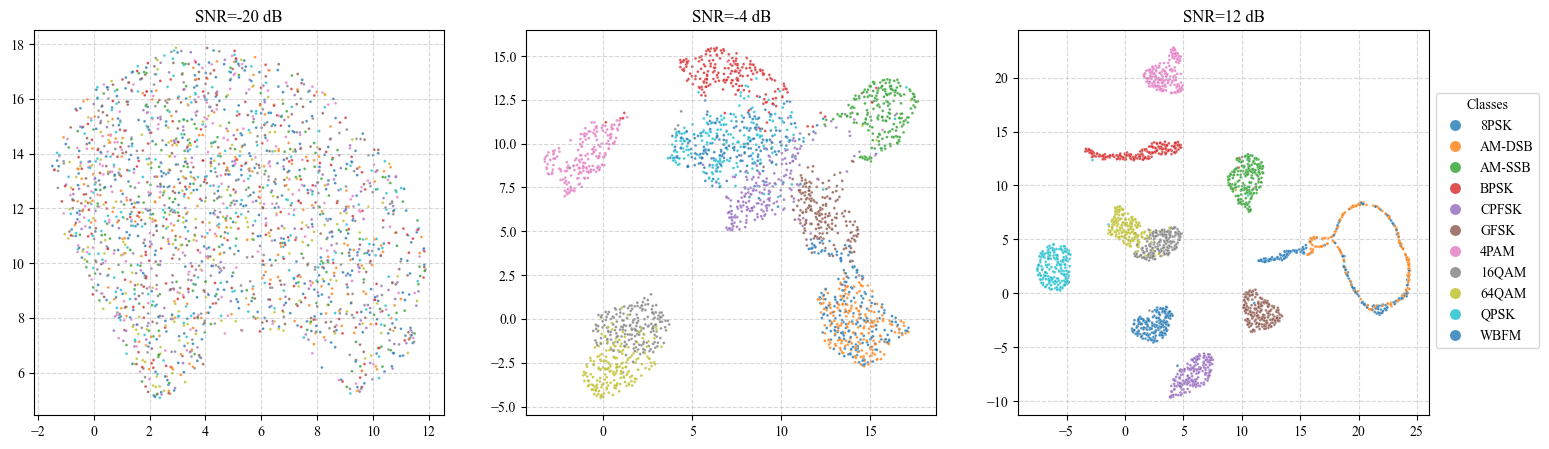

正在评估模型 /home/mount_data/bsh/PSGFormer/outputs/WaveletCNN/RML128b__0.652 在 SNR=-20 dB 上的性能...


Parallel Warming up (num_proc=8):   0%|          | 0/240000 [00:00<?, ? examples/s]

test 94
正在使用 12000 个样本建立 UMAP 基准流形...


/home/zjut/miniconda3/envs/signal/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


正在评估模型 /home/mount_data/bsh/PSGFormer/outputs/WaveletCNN/RML128b__0.652 在 SNR=-4 dB 上的性能...


Parallel Warming up (num_proc=8):   0%|          | 0/240000 [00:00<?, ? examples/s]

... (3 outputs left out)

Parallel Warming up (num_proc=8):   0%|          | 0/240000 [00:00<?, ? examples/s]

test 94
正在使用 12000 个样本建立 UMAP 基准流形...


/home/zjut/miniconda3/envs/signal/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


<Figure size 640x480 with 0 Axes>

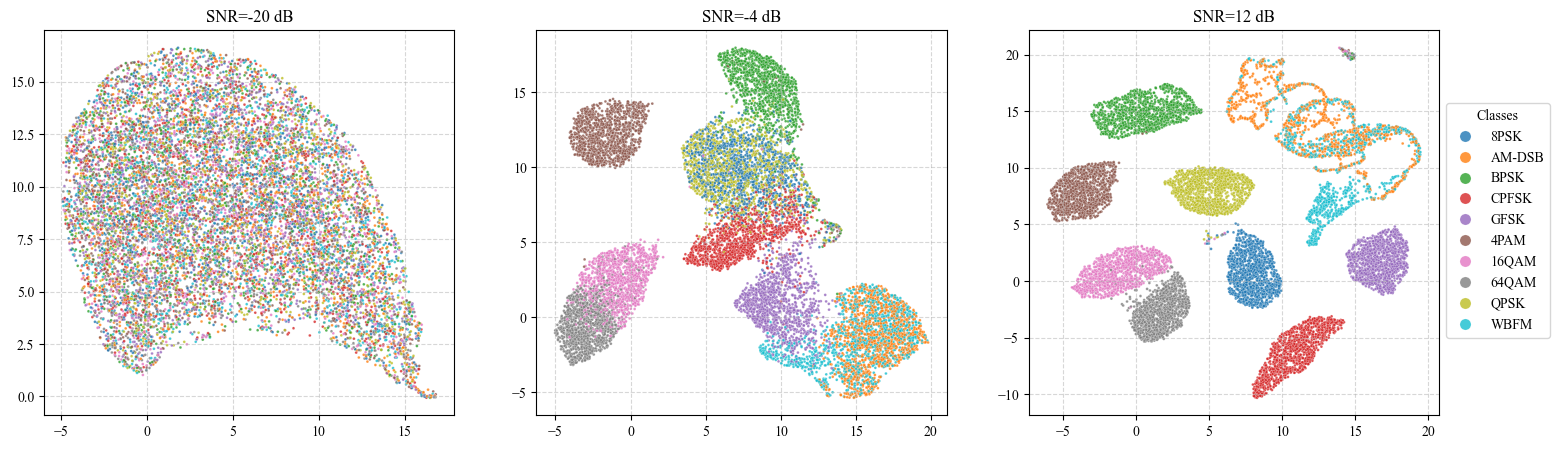

正在评估模型 /home/mount_data/bsh/PSGFormer/outputs/WaveletCNN/RML1024__17_0.621 在 SNR=-20 dB 上的性能...


Loading dataset from disk:   0%|          | 0/26 [00:00<?, ?it/s]

Parallel Warming up (num_proc=8):   0%|          | 0/1533792 [00:00<?, ? examples/s]

test 461
正在使用 20000 个样本建立 UMAP 基准流形...


/home/zjut/miniconda3/envs/signal/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


正在评估模型 /home/mount_data/bsh/PSGFormer/outputs/WaveletCNN/RML1024__17_0.621 在 SNR=-4 dB 上的性能...


... (6 outputs left out)

Parallel Warming up (num_proc=8):   0%|          | 0/1533792 [00:00<?, ? examples/s]

test 461
正在使用 20000 个样本建立 UMAP 基准流形...


/home/zjut/miniconda3/envs/signal/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


<Figure size 640x480 with 0 Axes>

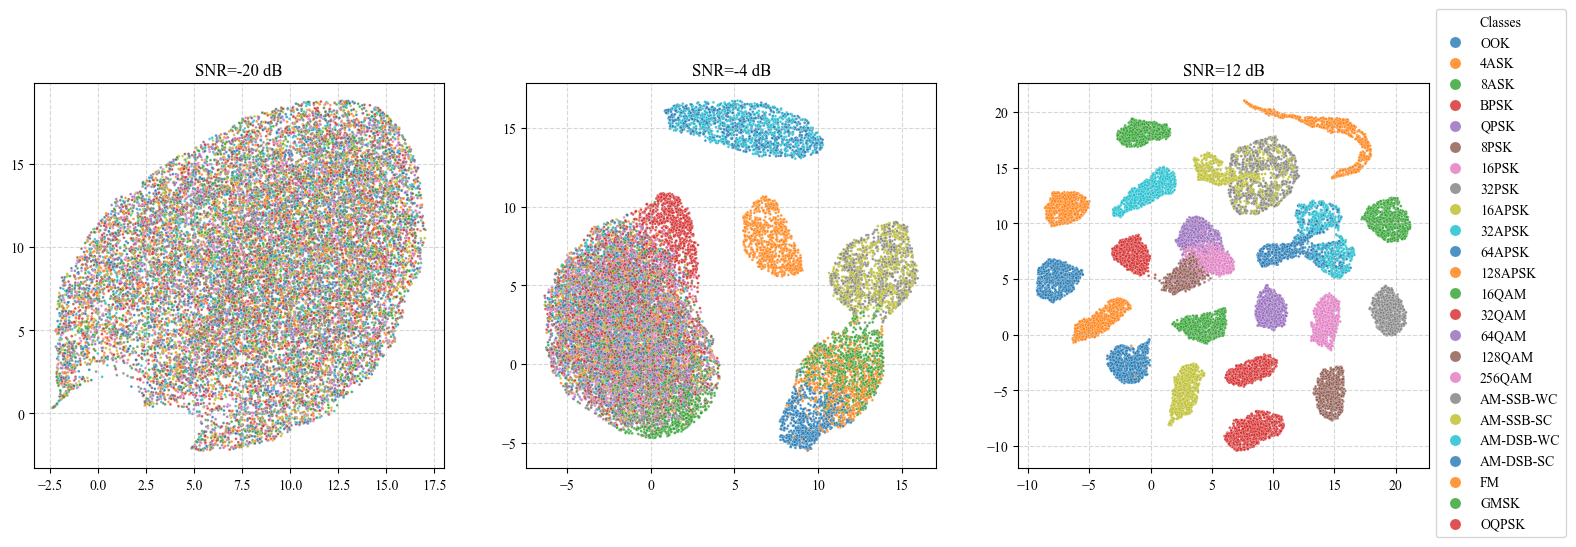

<Figure size 640x480 with 0 Axes>

In [ ]:
import csv, torchmetrics, torch, json
from omegaconf import OmegaConf
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from provider import *
from inference_class import InferenceClass
from utils.metrics import UmapVis

FONTS = {
    '等宽': 'Noto Sans Mono CJK SC',
    '宋体': 'Noto Serif CJK SC',
    '黑体': 'Noto Sans CJK SC',
    '思源宋体': 'Source Han Serif SC',
    '思源等宽': 'Source Han Mono SC',
    '微软雅黑': 'SimHei',
    'Times New Roman': 'Times New Roman'
}
plt.rcParams["font.family"] = [FONTS['Times New Roman'], FONTS['宋体']]

model_dirs = [
        #TechRec
        # '/home/mount_data/bsh/PSGFormer/outputs/WaveletCNN/TechRec__0.8837',
        # '/home/mount_data/bsh/PSGFormer/outputs/CNN1D/TechRec__version_1',
        # '/home/mount_data/bsh/PSGFormer/outputs/MCLDNN/TechRec__version_1',
        
        # '/home/mount_data/bsh/PSGFormer/outputs/FEA_T/TechRec__version_1',
        # '/home/mount_data/bsh/PSGFormer/outputs/SigFormer/TechRec__version_1',
        # '/home/mount_data/bsh/PSGFormer/outputs/IQFormer/TechRec_STFT__version_3',
        # '/home/mount_data/bsh/PSGFormer/outputs/ALWNN/TechRec__version_2',
        # '/home/mount_data/bsh/PSGFormer/outputs/ULCNN/TechRec__version_1',
        
        #RML128
        '/home/mount_data/bsh/PSGFormer/outputs/WaveletCNN/RML128__0.633',
        # '/home/mount_data/bsh/PSGFormer/outputs/CNN1D/RML128__version_1',
        # '/home/mount_data/bsh/PSGFormer/outputs/IQFormer/RML128_STFT__version_1',
        # '/home/mount_data/bsh/PSGFormer/outputs/ALWNN/RML128__version_2',
        # '/home/mount_data/bsh/PSGFormer/outputs/ULCNN/RML128__version_1',
        
        #RML128b
        '/home/mount_data/bsh/PSGFormer/outputs/WaveletCNN/RML128b__0.652',
        # '/home/mount_data/bsh/PSGFormer/outputs/CNN1D/RML128b__version_1',
        # '/home/mount_data/bsh/PSGFormer/outputs/IQFormer/RML128b_STFT__version_1',
        # '/home/mount_data/bsh/PSGFormer/outputs/ALWNN/RML128b__version_2',
        # '/home/mount_data/bsh/PSGFormer/outputs/ULCNN/RML128b__version_1',
        
        #RML1024
        '/home/mount_data/bsh/PSGFormer/outputs/WaveletCNN/RML1024__17_0.621',
        # '/home/mount_data/bsh/PSGFormer/outputs/CNN1D/RML1024__version_1',
        # '/home/mount_data/bsh/PSGFormer/outputs/IQFormer/RML1024_STFT__version_5',
        # '/home/mount_data/bsh/PSGFormer/outputs/ALWNN/RML1024__version_1',
        # '/home/mount_data/bsh/PSGFormer/outputs/ULCNN/RML1024__version_2',
        
        
]
DEVICE = 'cuda:1'  #因为循环多次加载模型 jupyter不自动释放gpu（无解）,初始化一个变量来防止放置到多个gpu上
SNRS=[-20,-4,12]

for model_dir in model_dirs:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for i, snr in enumerate(SNRS):
        print(f"正在评估模型 {model_dir} 在 SNR={snr} dB 上的性能...")
        cfg = OmegaConf.load(Path(model_dir) / 'config.yaml')
        cfg.dataset.snr=snr
        #数据集
        _, batchld, _, classes = SigData_provider('test', cfg)
        #模型
        model = InferenceClass(model_dir, DEVICE)
        #指标混淆矩阵 snr曲线
        umap=UmapVis(n_components=2,min_dist=0.5).to(DEVICE)
        for batch in batchld:
            output=model.infer_step(batch)
            logits,pred, label = output['logits'],output['pred'], output['target']
            
            umap.update(logits, label[:, 1])

        umap_feature,umap_labels=umap.compute()
        
        umap.plot(umap_feature, umap_labels,ax=axes[i], title=f"SNR={snr} dB",classes=classes)
        
            
    handles, labels = axes[0].get_legend_handles_labels()
    axes[0].legend().remove()  # 移除第一个子图的图例（如果存在）
    axes[1].legend().remove()  # 移除第二个子图的图例（如果存在）
    axes[2].legend().remove()  # 移除第三个子图的
    # 3. 创建 Figure 级别的全局图例，精确放置在整张大图的最右侧
    fig.legend(
        handles, 
        labels, 
        loc='center left', 
        bbox_to_anchor=(0.9, 0.5), # 基于整个 Figure 坐标系，1.01 表示刚好超出右边界
        title="Classes",
        markerscale=4,  # 图例中标记的大小
    )
    plt.savefig(f'./plot/{cfg.dataset.name}_umap.png', dpi=300)
    plt.show()
